# Introduction to Machine Learning – Lab 3
## k-Means Clustering with Log-Transformed Features and Min-Max Scaling

### Objective
This notebook repeats the clustering of notebook 08 after taking the logarithm of a few skewed columns. Min-max scaling stays as it was, so a difference in the results comes from the logarithm alone.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from clustering import (
    BLUE,
    N_INIT,
    SEED,
    agreement_table,
    fit_models,
    inertia_table,
    plot_clusters,
    plot_elbow,
    plot_silhouettes,
    reduce_to_thresholds,
    silhouette_table,
    style_axes,
)
from preprocessing import (
    CONTINUOUS,
    LOG_FEATURES,
    ORDINAL,
    drop_incomplete,
    fill_missing,
    log_features,
    make_preprocessor,
    make_scaler,
    prepare_data,
)
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

### Data preparation
The houses are loaded, the two houses with whole blocks of empty cells are dropped, the remaining gaps are filled and the categorical features are encoded. Notebook 08 explains these choices.

In [2]:
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
X_complete, y_complete = drop_incomplete(X, y)
X_complete = fill_missing(X_complete)
encoded_complete = make_preprocessor("onehot", min_frequency=5).fit_transform(X_complete, y_complete)

onehot = [col for col in encoded_complete.columns if col not in X_complete.columns]
ordinal = [col for col in encoded_complete.columns if col in ORDINAL]
numeric = [col for col in encoded_complete.columns if col not in onehot + ordinal]
column_types = {"One-hot": onehot, "Ordinal": ordinal, "Numeric": numeric}

assert encoded_complete.isna().sum().sum() == 0
assert len(onehot) + len(ordinal) + len(numeric) == encoded_complete.shape[1]

print(f"{len(encoded_complete):,} houses, {encoded_complete.shape[1]} columns")
print(f"One-hot: {len(onehot)}, ordinal: {len(ordinal)}, numeric: {len(numeric)}")

2,923 houses, 205 columns
One-hot: 151, ordinal: 21, numeric: 33


### Log transform
A column is **skewed** when most houses sit at small values and a few reach very large ones. Skew 0 means a symmetric column, a positive skew means a long tail to the right. The transform `log(1 + x)` (`np.log1p`) pulls such a tail in, and the `1 +` keeps an area of 0 at 0 instead of minus infinity.

The logarithm only helps some columns, so all 19 continuous columns are tested against one rule. A column passes if it has fewer than half zeros, a skew above 0.5, and if the logarithm at least halves its absolute skew.

In [3]:
continuous = encoded_complete[CONTINUOUS]
logged_continuous = np.log1p(continuous)

skew_table = pd.DataFrame(
    {
        "Skew before": continuous.skew(),
        "Skew after log": logged_continuous.skew(),
        "Share of zeros": (continuous == 0).mean(),
    }
)
skew_table["Fewer than half zeros"] = skew_table["Share of zeros"] < 0.5
skew_table["Skew above 0.5"] = skew_table["Skew before"] > 0.5
skew_table["Log at least halves it"] = skew_table["Skew after log"].abs() <= skew_table["Skew before"].abs() / 2
skew_table["Passes"] = skew_table[["Fewer than half zeros", "Skew above 0.5", "Log at least halves it"]].all(axis=1)

passing = skew_table.index[skew_table["Passes"]]
assert set(passing) == set(LOG_FEATURES)

display(skew_table.round(2).sort_values(["Passes", "Skew before"], ascending=False))
print(f"Columns that pass: {', '.join(passing)}")

,Skew before,Skew after log,Share of zeros,Fewer than half zeros,Skew above 0.5,Log at least halves it,Passes
Lot Area,13.20,-0.53,0.00,True,True,True,True
Open Porch SF,2.49,-0.05,0.44,True,True,True,True
1st Flr SF,0.94,-0.01,0.00,True,True,True,True
Gr Liv Area,0.88,-0.06,0.00,True,True,True,True
Misc Val,22.22,5.23,0.97,False,True,True,False
Pool Area,18.74,16.36,1.00,False,True,False,False
Low Qual Fin SF,12.10,8.57,0.99,False,True,False,False
3Ssn Porch,11.39,8.84,0.99,False,True,False,False
BsmtFin SF 2,4.14,2.45,0.88,False,True,False,False
Enclosed Porch,4.02,1.97,0.84,False,True,True,False


Columns that pass: Lot Area, 1st Flr SF, Gr Liv Area, Open Porch SF


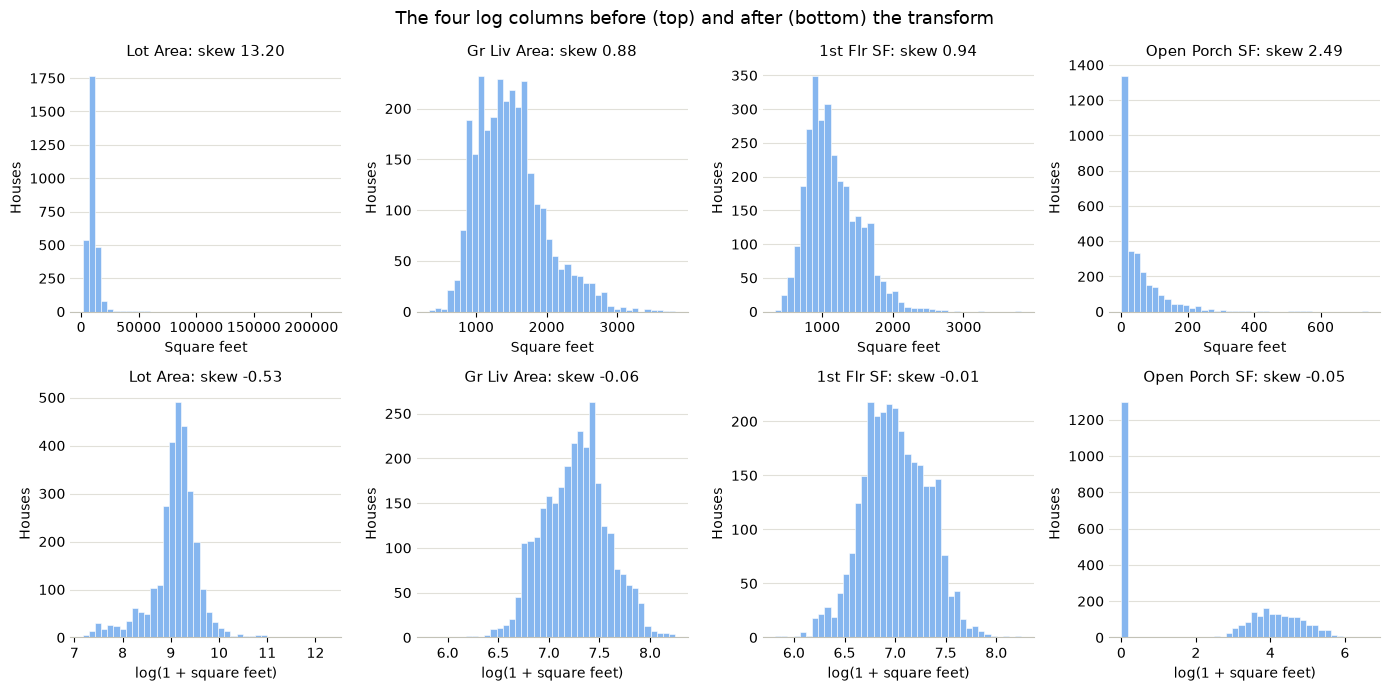

In [4]:
fig, axes = plt.subplots(2, len(LOG_FEATURES), figsize=(14, 7))
for column, feature in enumerate(LOG_FEATURES):
    panels = [(continuous[feature], "Square feet"), (logged_continuous[feature], "log(1 + square feet)")]
    for row, (values, xlabel) in enumerate(panels):
        ax = axes[row, column]
        ax.hist(values, bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
        ax.set_title(f"{feature}: skew {values.skew():.2f}", fontsize=11)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Houses")
        style_axes(ax)
fig.suptitle("The four log columns before (top) and after (bottom) the transform", fontsize=13)
plt.tight_layout()
plt.show()

In [5]:
lot_area = encoded_complete["Lot Area"]
log_then_minmax = make_scaler().fit_transform(np.log1p(lot_area).to_frame()).squeeze()
minmax_then_log = np.log1p((lot_area - lot_area.min()) / (lot_area.max() - lot_area.min()))
zscore = (lot_area - lot_area.mean()) / lot_area.std(ddof=0)

print("Skew of Lot Area, depending on the order:")
print(f"  Raw: {lot_area.skew():.2f}")
print(f"  Log first, then min-max: {log_then_minmax.skew():.2f}")
print(f"  Min-max first, then log: {minmax_then_log.skew():.2f}")
print(f"Lowest Lot Area after z-score: {zscore.min():.2f}, houses below 0: {(zscore < 0).sum():,}")

Skew of Lot Area, depending on the order:
  Raw: 13.20
  Log first, then min-max: -0.53
  Min-max first, then log: 9.37
Lowest Lot Area after z-score: -1.13, houses below 0: 1,732


#### Interpretation of the log transform
- **What was tried:** all 19 continuous columns went through the same rule: fewer than half zeros, a skew above 0.5, and a logarithm that at least halves the absolute skew.
- **Chosen columns:** four columns pass. `Lot Area` goes from a skew of 13.20 to -0.53, `Open Porch SF` from 2.49 to -0.05, `1st Flr SF` from 0.94 to -0.01 and `Gr Liv Area` from 0.88 to -0.06. The histograms show the long right tails turning into roughly symmetric shapes.
- **Weakest of the four:** `Open Porch SF` passes, but its 44% zeros stay as a spike at 0 next to a hump of real porches. Its skew is close to 0 because the two parts balance, and the column does not become bell-shaped.
- **Rejected because the skew only flips:** `Lot Frontage` moves from 1.09 to -1.07, as strong as before on the other side. `Bsmt Unf SF` (0.92 to -2.15) and `BsmtFin SF 1` (0.82 to -0.62) fail for the same reason.
- **Rejected because zeros get worse:** `Total Bsmt SF` goes from 0.40 to -4.98 and `Garage Area` from 0.21 to -3.53. These columns were hardly skewed, and only 3% and 5% of the houses are zeros. The logarithm stretches the small values, so the zeros end up far below all the other houses, as new low outliers.
- **Rejected because more than half are zeros:** `Wood Deck SF` (52%), `2nd Flr SF` (57%) and `Mas Vnr Area` (60%) reach a good skew of 0.16, 0.31 and 0.54, but only by separating zeros from all other houses. The seven columns with 84% zeros or more, such as `Pool Area`, are nearly empty, and the logarithm leaves all of them strongly skewed.
- **Not tested:** discrete, ordinal and one-hot columns are not continuous measurements. Counts and years have no long tail of the same kind, the gaps between grades are already an assumption, and a 0/1 column has nothing to compress.
- **Why the logarithm comes before the scaling:** it works on the real areas, where a large lot is many times a small one. After min-max scaling nearly all values are tiny, and for tiny values `log(1 + x)` is almost `x`, so the skew of `Lot Area` stays at 9.37 instead of reaching -0.53. After z-score scaling 1,732 houses have negative values, reaching -1.13, and below -1 the logarithm does not exist at all.

In [6]:
# Fitted on all houses: k-means has no train/test split
logged = log_features(encoded_complete)
scaled = make_scaler().fit_transform(logged)

assert np.allclose(scaled.min(), 0) and np.allclose(scaled.max(), 1)
assert scaled[onehot].equals(encoded_complete[onehot])
assert logged.drop(columns=LOG_FEATURES).equals(encoded_complete.drop(columns=LOG_FEATURES))

without_log = make_scaler().fit_transform(encoded_complete)

print(f"Columns changed by the logarithm: {len(LOG_FEATURES)} of {scaled.shape[1]}")
print("Median of the four columns after min-max scaling:")
display(pd.DataFrame({"Without log": without_log[LOG_FEATURES].median(), "With log": scaled[LOG_FEATURES].median()}).round(3))
print("Variance of the four columns after min-max scaling:")
display(pd.DataFrame({"Without log": without_log[LOG_FEATURES].var(), "With log": scaled[LOG_FEATURES].var()}).round(4))

Columns changed by the logarithm: 4 of 205
Median of the four columns after min-max scaling:


,Without log,With log
Lot Area,0.038,0.388
Gr Liv Area,0.318,0.600
1st Flr SF,0.215,0.482
Open Porch SF,0.036,0.504


Variance of the four columns after min-max scaling:


,Without log,With log
Lot Area,0.0013,0.0099
Gr Liv Area,0.0195,0.0174
1st Flr SF,0.0117,0.0172
Open Porch SF,0.0081,0.1060


#### Interpretation of the scaled log columns
- **Few columns change:** 4 of the 205 columns differ from notebook 08, and all others have the same values.
- **Medians move up:** with the raw values, a few huge lots stretch the 0-1 range, so the median `Lot Area` sits at 0.038. After the logarithm it sits at 0.388, and the houses use the range much better. `Open Porch SF` moves from 0.036 to 0.504.
- **Variance:** `Open Porch SF` goes from 0.0081 to 0.1060 and `Lot Area` from 0.0013 to 0.0099, so these two columns gain influence on distances and on PCA. `Gr Liv Area` barely changes (0.0195 to 0.0174). The logarithm thus does more here than improve a shape: under min-max scaling it also changes how much a column counts.

### Principal component analysis

In [7]:
pca, reduced, component_counts = reduce_to_thresholds(scaled)
shares = pca.explained_variance_ratio_
cumulative = shares.cumsum()

variance_table = pd.DataFrame(
    {
        "Variance kept": [f"{t:.0%}" for t in component_counts],
        "Components": list(component_counts.values()),
        "Share of the columns": [f"{count / scaled.shape[1]:.1%}" for count in component_counts.values()],
    }
)
top_columns = pd.Series(np.abs(pca.components_[0]), index=scaled.columns).nlargest(6).round(3)

display(variance_table)
print(f"PC1: {shares[0]:.2%}, PC2: {shares[1]:.2%}, PC3: {shares[2]:.2%}")
print("Columns with the largest absolute weight in PC1:")
print(top_columns.to_string())

,Variance kept,Components,Share of the columns
0,98%,113,55.1%
1,95%,82,40.0%
2,90%,59,28.8%
3,80%,36,17.6%


PC1: 13.53%, PC2: 8.80%, PC3: 5.44%
Columns with the largest absolute weight in PC1:
Foundation_PConc        0.329
Exterior 1st_VinylSd    0.285
Exterior 2nd_VinylSd    0.283
Garage Type_Attchd      0.222
Garage Type_Detchd      0.216
Year Remod/Add          0.208


#### Interpretation of the principal components
- **Reduction:** the component counts are 113, 82, 59 and 36 for the four thresholds. So 98% of the variance takes 55.1% of the columns and 80% takes 17.6%.
- **First components:** PC1 holds 13.53%, PC2 8.80% and PC3 5.44% of the variance.
- **What leads PC1:** the top columns are `Foundation_PConc`, `Exterior 1st_VinylSd`, `Exterior 2nd_VinylSd`, `Garage Type_Attchd`, `Garage Type_Detchd` and `Year Remod/Add`. Five of the six are one-hot columns about the building type. None of the four log columns is among them, so the logarithm has not changed what PC1 is mainly about.

### Elbow method

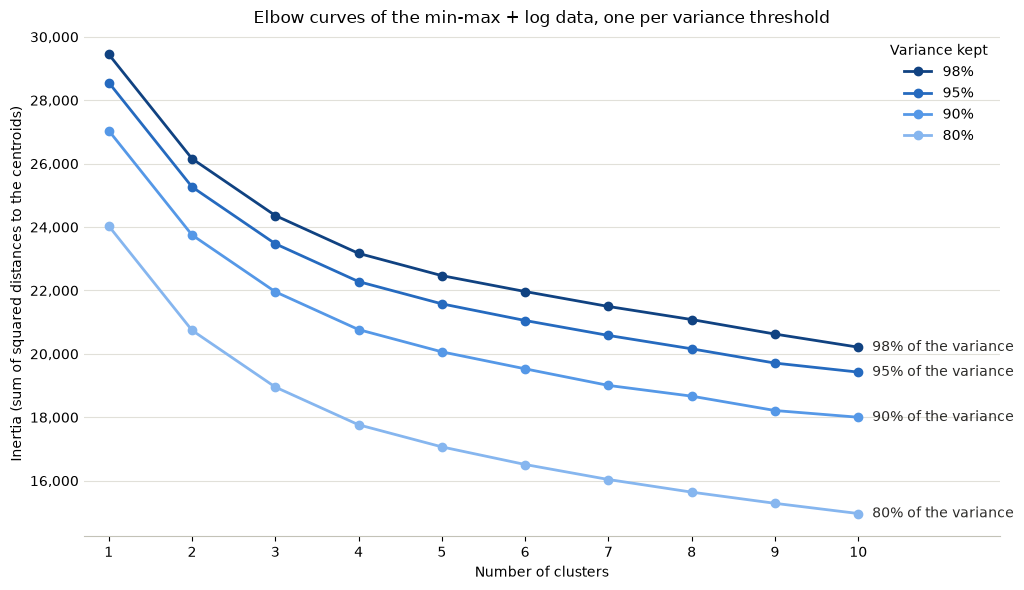

In [8]:
cluster_range = range(1, 11)
inertia = inertia_table(reduced, component_counts, cluster_range)

plot_elbow(inertia, "Elbow curves of the min-max + log data, one per variance threshold")

In [9]:
drop_per_cluster = inertia.pct_change().dropna().mul(-100).round(1)
drop_per_cluster.index.name = "Cluster added"

kept = pd.Series({f"{t:.0%}": cumulative[count - 1] for t, count in component_counts.items()})
height = pd.DataFrame(
    {
        "Inertia with 1 cluster": inertia.loc[1],
        "Compared with 98%": inertia.loc[1] / inertia.loc[1, "98%"],
        "Variance kept compared with 98%": kept / kept["98%"],
    }
)

print("Inertia:")
display(inertia.round(0).astype(int))
print("Percentage drop in inertia when one more cluster is added:")
display(drop_per_cluster)
print("Height of the curves:")
display(height.round(3))

Inertia:


,98%,95%,90%,80%
Clusters,,,,
1,29450,28559,27043,24035
2,26157,25266,23750,20743
3,24364,23473,21959,18953
4,23170,22280,20766,17763
5,22468,21578,20065,17067
6,21967,21053,19529,16511
7,21495,20582,19005,16037
8,21083,20160,18667,15639
9,20625,19710,18213,15286


Percentage drop in inertia when one more cluster is added:


,98%,95%,90%,80%
Cluster added,,,,
2,11.2,11.5,12.2,13.7
3,6.9,7.1,7.5,8.6
4,4.9,5.1,5.4,6.3
5,3.0,3.1,3.4,3.9
6,2.2,2.4,2.7,3.3
7,2.1,2.2,2.7,2.9
8,1.9,2.1,1.8,2.5
9,2.2,2.2,2.4,2.3
10,2.0,1.4,1.2,2.1


Height of the curves:


,Inertia with 1 cluster,Compared with 98%,Variance kept compared with 98%
98%,29449.782,1.000,1.000
95%,28559.011,0.970,0.970
90%,27042.918,0.918,0.918
80%,24034.743,0.816,0.816


#### Interpretation of the elbow curves
- **What is plotted:** the inertia of a model is the sum, over all houses, of the squared distance from the house to the centroid of its cluster. The centroid is simply the mean of the houses in that cluster.
- **A curve that can only go down:** adding a centroid never moves a house further from its nearest center, so the curve keeps falling (at 90% from 27,043 to 18,002) whether or not the data holds groups. The useful signal is the place where the gain from one more cluster becomes small.
- **The bend:** at 90% the gains are 12.2%, 7.5%, 5.4% and 3.4% for the second to the fifth cluster. The sixth and seventh add 2.7% each, and the three after them 1.8%, 2.4% and 1.2%. The curve flattens after 5 clusters, but the change from 3.4% to 2.7% is small, so this is a soft bend and nothing like a corner.
- **Levels of the four curves:** one cluster gives an inertia of 29,450 at 98%, 28,559 at 95%, 27,043 at 90% and 24,035 at 80%. That inertia equals the number of houses times the variance kept, which is why the two columns of relative values in the last table agree (0.970, 0.918 and 0.816). The lower curves have less variance to explain, and this says nothing about the quality of their clusters.
- **Compare the shapes:** in the percentage table the four thresholds behave alike, with the fifth cluster adding between 3.0% and 3.9%. The shape carries the information, the height does not.

### Silhouette analysis

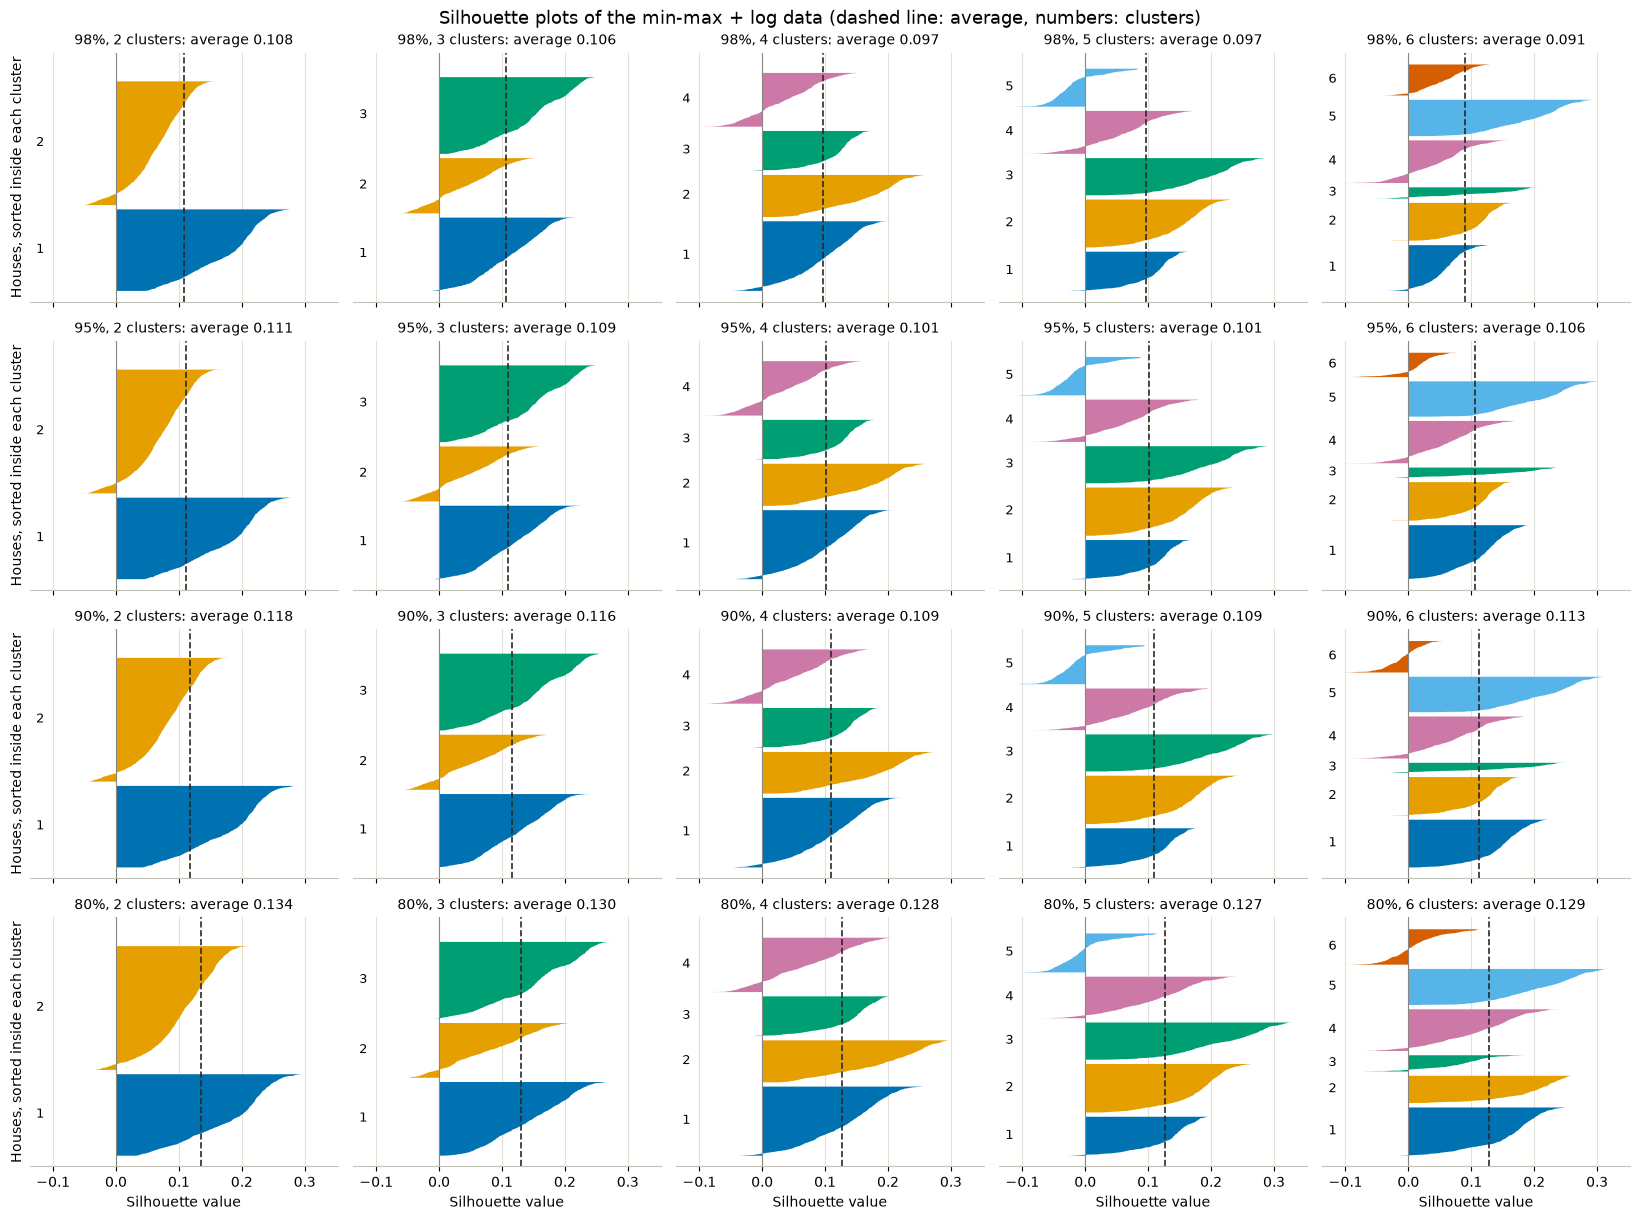

In [10]:
plot_silhouettes(
    reduced,
    component_counts,
    range(2, 7),
    "Silhouette plots of the min-max + log data (dashed line: average, numbers: clusters)",
)

In [11]:
silhouette = silhouette_table(reduced, component_counts, range(2, 9))

print("Average silhouette:")
display(silhouette.round(3))
print("Number of clusters with the highest average silhouette:")
print(silhouette.idxmax().to_string())

Average silhouette:


,98%,95%,90%,80%
Clusters,,,,
2,0.108,0.111,0.118,0.134
3,0.106,0.109,0.116,0.130
4,0.097,0.101,0.109,0.128
5,0.097,0.101,0.109,0.127
6,0.091,0.106,0.113,0.129
7,0.085,0.098,0.117,0.127
8,0.090,0.091,0.109,0.116


Number of clusters with the highest average silhouette:
98%    2
95%    2
90%    2
80%    2


#### Interpretation of the silhouette analysis
- **The measure:** for each house the silhouette compares `a`, the mean distance to its own cluster, with `b`, the mean distance to the nearest other cluster, as `(b - a) / max(a, b)`. It runs from -1 to 1. High values mean a clear membership, values near 0 a place at the border, and negative values a house closer to another cluster.
- **The shapes:** one colored shape per cluster, its houses sorted by value. Its thickness shows the size, its reach to the right the quality, and the dashed line the average.
- **What 0.1 says:** the averages lie between 0.085 and 0.134. Houses are on average barely closer to their own cluster than to a neighboring one, so the clusters run into each other. There is one cloud of houses with thicker and thinner regions, and the borders between clusters run through the cloud.
- **Preferred number of clusters:** 2 clusters have the highest average at all thresholds. At 90% the values are 0.118 for 2, 0.116 for 3, 0.109 for 4 and 5, 0.113 for 6 and 0.117 for 7. The rise to 0.117 at 7 clusters appears at this threshold only, and the next section shows that those models change with the seed, so it is not trustworthy.
- **Weak clusters:** at 5 clusters, cluster 5 has the most houses below 0, and cluster 4 also has a clear tail there.
- **Effect of the threshold:** the average at 5 clusters goes from 0.097 at 98% to 0.127 at 80%. The dropped components add small differences between all houses alike, so without them `a` and `b` lie further apart in relative terms, even if the same houses stay together.

### Choice of the number of clusters

In [12]:
test_threshold = 0.90
test_data = reduced[:, : component_counts[test_threshold]]
seeds = range(6)

rows = []
for k in range(2, 8):
    runs = [KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit_predict(test_data) for seed in seeds]
    pair_scores = [adjusted_rand_score(first, second) for first, second in combinations(runs, 2)]
    rows.append(
        {
            "Clusters": k,
            "Seed pairs": len(pair_scores),
            "Mean agreement": np.mean(pair_scores),
            "Lowest agreement": np.min(pair_scores),
            "Inertia drop (%)": drop_per_cluster.loc[k, "90%"],
            "Average silhouette": silhouette.loc[k, "90%"],
            "Cluster sizes (seed 0)": sorted(np.bincount(runs[0]).tolist()),
        }
    )

choice = pd.DataFrame(rows).set_index("Clusters")
with pd.option_context("display.max_colwidth", None):
    display(choice.round(3))

,Seed pairs,Mean agreement,Lowest agreement,Inertia drop (%),Average silhouette,Cluster sizes (seed 0)
Clusters,,,,,,
2,15,1.000,1.000,12.2,0.118,"[1161, 1762]"
3,15,0.999,0.999,7.5,0.116,"[785, 1044, 1094]"
4,15,0.991,0.984,5.4,0.109,"[565, 599, 774, 985]"
5,15,0.902,0.727,3.4,0.109,"[160, 552, 575, 649, 987]"
6,15,0.793,0.590,2.7,0.113,"[231, 392, 507, 515, 589, 689]"
7,15,0.726,0.537,2.7,0.117,"[213, 224, 290, 428, 502, 587, 679]"


In [13]:
n_clusters = 5

rows = []
for seed in [*seeds, SEED]:
    model = KMeans(n_clusters=n_clusters, n_init=N_INIT, random_state=seed).fit(test_data)
    rows.append({"Seed": seed, "Inertia": model.inertia_, "Cluster sizes": sorted(np.bincount(model.labels_).tolist())})

print(f"Chosen number of clusters: {n_clusters}")
print(f"Runs at {test_threshold:.0%} of the variance with each seed:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("Seed").round(1))

Chosen number of clusters: 5
Runs at 90% of the variance with each seed:


,Inertia,Cluster sizes
Seed,,
0,20109.5,"[160, 552, 575, 649, 987]"
1,20064.9,"[528, 546, 558, 604, 687]"
2,20064.6,"[528, 556, 562, 589, 688]"
3,20064.9,"[529, 546, 556, 605, 687]"
4,20064.7,"[528, 555, 565, 586, 689]"
5,20064.9,"[530, 539, 558, 612, 684]"
42,20064.6,"[528, 556, 558, 593, 688]"


#### Interpretation of the number of clusters
- **What was tried:** a seed fixes the random start of k-means. Six seeds per number of clusters, at 90% of the variance, give 15 pairs of runs for each row of the table. The **adjusted Rand index** compares the two groupings of each pair and ignores the cluster numbers. A value of 1 means that the runs found the same groups, and 0 is the level of pure chance.
- **What came out:** 2, 3 and 4 clusters are very stable, with means of 1.000, 0.999 and 0.991. At 5 clusters the mean is only 0.902 and the lowest pair 0.727. At 6 and 7 clusters the means are 0.793 and 0.726.
- **Where the weak spot at 5 comes from:** the seed table shows that a single run causes it. Seed 0 lands on another solution, with sizes 160, 552, 575, 649 and 987 and an inertia of 20,109.5. The other six runs all reach 20,064.6 to 20,064.9, with five groups of 528 to 689 houses. Seed 0 is simply worse, because a lower inertia is what k-means aims for. The seed 42 model used below has the lowest inertia in the table, 20,064.6.
- **Choice:** 5 clusters, because the elbow flattens after the fifth cluster (3.4%, then 2.7%), because 2 clusters only divide the houses into 1,161 and 1,762, and because notebooks 08, 08.1, 08.2 and 08.3 have to share one number of clusters to be comparable.
- **Evidence against it:** notebook 09 shows this as the least stable of the four preparations at 5 clusters. Looking at stability alone, 4 clusters (0.991) beat 5 clusters (0.902) here. The silhouette also prefers 2 clusters (0.118) to 5 (0.109). The soft bend gives no strong signal either.
- **Rejected:** 2 and 3 clusters give too little detail, 4 clusters would break the comparison with the other notebooks, and 6 and 7 clusters vary clearly from seed to seed.

### Final models and cluster scatter plots

In [14]:
models = fit_models(reduced, component_counts, n_clusters)
labels_at_98 = models[0.98].labels_

rows = []
for threshold, model in models.items():
    count = component_counts[threshold]
    values = silhouette_samples(reduced[:, :count], model.labels_)
    sizes = np.bincount(model.labels_)
    rows.append(
        {
            "Variance kept": f"{threshold:.0%}",
            "Components": count,
            **{f"Cluster {number}": size for number, size in enumerate(sizes, start=1)},
            "Inertia": model.inertia_,
            "Average silhouette": values.mean(),
            "Negative silhouette": (values < 0).mean(),
            "Houses not in their 98% cluster": (model.labels_ != labels_at_98).sum(),
        }
    )

final_models = pd.DataFrame(rows).set_index("Variance kept")
display(final_models.round(3))

,Components,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Inertia,Average silhouette,Negative silhouette,Houses not in their 98% cluster
Variance kept,,,,,,,,,,
98%,113,559,682,530,611,541,22468.079,0.097,0.185,0
95%,82,558,687,528,603,547,21578.290,0.101,0.179,11
90%,59,558,688,528,593,556,20064.625,0.109,0.168,21
80%,36,555,691,530,592,555,17066.574,0.127,0.138,23


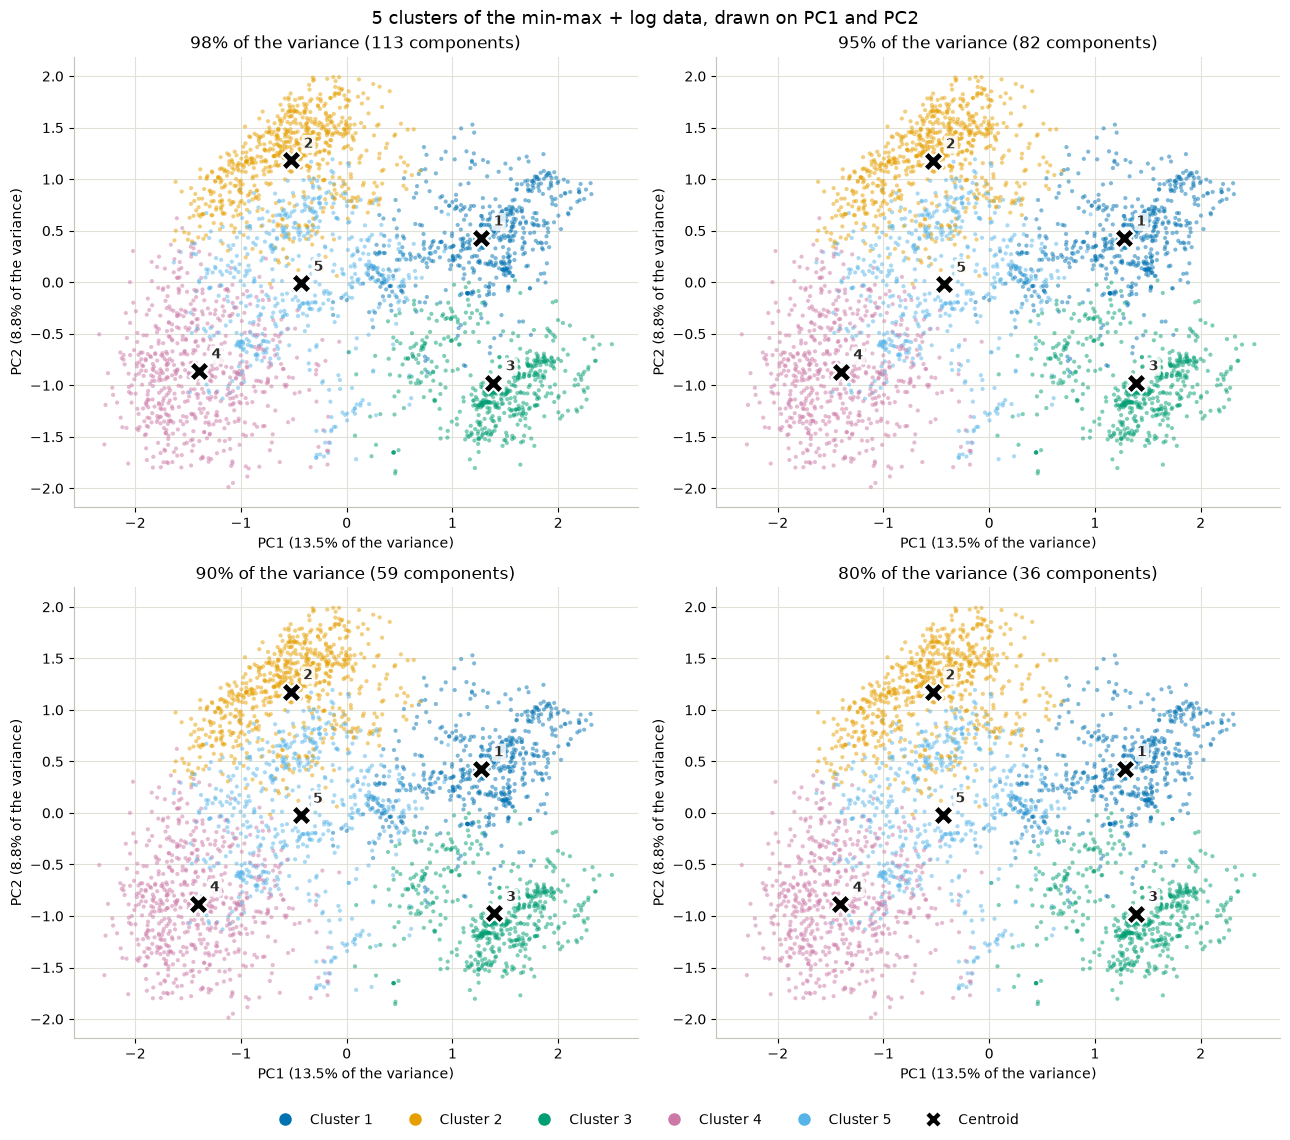

In [15]:
panels = {
    f"{threshold:.0%} of the variance ({component_counts[threshold]} components)": (pca, reduced, model)
    for threshold, model in models.items()
}
plot_clusters(panels, f"{n_clusters} clusters of the min-max + log data, drawn on PC1 and PC2")

In [16]:
threshold_agreement = agreement_table({f"{t:.0%}": model.labels_ for t, model in models.items()})
pair_scores = threshold_agreement.to_numpy()[np.triu_indices(len(threshold_agreement), k=1)]

centroid_shift = max(
    np.abs(model.cluster_centers_[:, :2] - models[0.98].cluster_centers_[:, :2]).max() for model in models.values()
)
visible = pd.Series({f"{t:.0%}": shares[:2].sum() / cumulative[count - 1] for t, count in component_counts.items()})

print("Adjusted Rand index between the thresholds:")
display(threshold_agreement.round(3))
print(f"Lowest agreement between two thresholds: {pair_scores.min():.3f}")
print(f"Largest move of a centroid on PC1 or PC2 compared with 98%: {centroid_shift:.3f}")
print(f"Standard deviation of the houses on PC1 / PC2: {reduced[:, 0].std():.3f} / {reduced[:, 1].std():.3f}")
print("Share of the kept variance that PC1 and PC2 show:")
print(visible.map("{:.1%}".format).to_string())

Adjusted Rand index between the thresholds:


,98%,95%,90%,80%
98%,1.000,0.990,0.982,0.980
95%,0.990,1.000,0.992,0.986
90%,0.982,0.992,1.000,0.992
80%,0.980,0.986,0.992,1.000


Lowest agreement between two thresholds: 0.980
Largest move of a centroid on PC1 or PC2 compared with 98%: 0.025
Standard deviation of the houses on PC1 / PC2: 1.179 / 0.951
Share of the kept variance that PC1 and PC2 show:
98%    22.8%
95%    23.5%
90%    24.8%
80%    27.9%


#### Interpretation of the final models
- **Are there differences?** Very few. Against the 98% model, 11, 21 and 23 houses change cluster at 95%, 90% and 80%. All pairs of thresholds agree with an adjusted Rand index of 0.980 or more. In the scatter plots no difference can be seen by eye.
- **Why the dots stay put:** a lower threshold keeps fewer columns of the same PCA, and PC1 and PC2 are always among them. So the dots are the same in all four panels. The centroids move by at most 0.025, compared with a spread of the houses of 1.179 on PC1 and 0.951 on PC2.
- **What is dropped:** going from 98% to 80% removes 77 components that hold little variance each. They contribute little to the distance between two houses, so the nearest centroid of a house rarely changes.
- **Sizes and scores:** the largest shift in size is 19 houses (cluster 4, 592 to 611). Inertia falls from 22,468 to 17,067, the average silhouette rises from 0.097 to 0.127, and negative silhouettes fall from 18.5% to 13.8%. These changes come from measuring fewer dimensions, because the membership of the houses stays nearly the same.
- **Why colors mix:** the picture is a flat view of a model built on up to 113 components. The two axes hold between 22.8% and 27.9% of the kept variance. Light blue cluster 5, in the middle, overlaps its neighbours most, which fits its weak silhouette.